DATASET LOADING

In [44]:
import pandas as pd 

baseline = pd.read_csv(r"C:\Users\DELL\Desktop\CRONIC KIDNEY DISEASES\datasets\baseline.csv")
followup = pd.read_csv(r"C:\Users\DELL\Desktop\CRONIC KIDNEY DISEASES\datasets\followup.csv")

print("Baseline dataset:")
print(baseline.head())

print("\nFollow-up dataset:")
print(followup.head())

Baseline dataset:
  usubjid  trt01pn randfl ittfl trtfl  blgfr blglp1  \
0  id0001        0      Y     Y     Y     54      N   
1  id0002        1      Y     Y     Y     27      N   
2  id0003        1      Y     Y     Y     50      N   
3  id0004        0      Y     Y     Y     47      N   
4  id0005        0      Y     Y     Y     75      N   

                                   strata  
0  Screening eGFR 45 to <60 mL/min/1.73m2  
1  Screening eGFR 45 to <60 mL/min/1.73m2  
2  Screening eGFR 45 to <60 mL/min/1.73m2  
3  Screening eGFR 45 to <60 mL/min/1.73m2  
4  Screening eGFR 60 to <90 mL/min/1.73m2  

Follow-up dataset:
  usubjid randfl ittfl trtfl anl01fl  aval  base   paramcd  \
0  id0001      Y     Y     Y       Y    54    54  GFRBSCRT   
1  id0001      Y     Y     Y       Y    51    54  GFRBSCRT   
2  id0001      Y     Y     Y       Y    61    54  GFRBSCRT   
3  id0001      Y     Y     Y       Y    63    54  GFRBSCRT   
4  id0001      Y     Y     Y       Y    53    54  GFRBSCR

In [45]:
print("Baseline  :",baseline.shape)
print("follow up  :",followup.shape)

Baseline  : (5000, 8)
follow up  : (41800, 12)


In [46]:
print("Baseline columns :",baseline.columns)
print("follow up columns :",followup.columns)

Baseline columns : Index(['usubjid', 'trt01pn', 'randfl', 'ittfl', 'trtfl', 'blgfr', 'blglp1',
       'strata'],
      dtype='object')
follow up columns : Index(['usubjid', 'randfl', 'ittfl', 'trtfl', 'anl01fl', 'aval', 'base',
       'paramcd', 'param', 'ady', 'avisitn', 'avisit'],
      dtype='object')


In [47]:

baseline = baseline.rename(columns={
    "usubjid": "patient_id",
    "trt01pn": "treatment_group",
    "randfl": "randomized_flag",
    "ittfl": "itt_flag",
    "trtfl": "treatment_flag",
    "blgfr": "baseline_egfr",
    "blglp1": "baseline_glp1",
    "strata": "egfr_category"
})

print(baseline.columns)


Index(['patient_id', 'treatment_group', 'randomized_flag', 'itt_flag',
       'treatment_flag', 'baseline_egfr', 'baseline_glp1', 'egfr_category'],
      dtype='object')


In [48]:

followup = followup.rename(columns={
    "usubjid": "patient_id",
    "randfl": "randomized_flag",
    "ittfl": "itt_flag",
    "trtfl": "treatment_flag",
    "anl01fl": "analysis_flag",
    "aval": "egfr_value",
    "base": "baseline_egfr",
    "paramcd": "parameter_code",
    "param": "parameter_name",
    "ady": "study_day",
    "avisitn": "visit_number",
    "avisit": "visit_label"
})

print(followup.columns)


Index(['patient_id', 'randomized_flag', 'itt_flag', 'treatment_flag',
       'analysis_flag', 'egfr_value', 'baseline_egfr', 'parameter_code',
       'parameter_name', 'study_day', 'visit_number', 'visit_label'],
      dtype='object')


In [49]:
print("Baseline :",baseline.dtypes)
print("Follow up :",followup.dtypes)

Baseline : patient_id         object
treatment_group     int64
randomized_flag    object
itt_flag           object
treatment_flag     object
baseline_egfr       int64
baseline_glp1      object
egfr_category      object
dtype: object
Follow up : patient_id         object
randomized_flag    object
itt_flag           object
treatment_flag     object
analysis_flag      object
egfr_value          int64
baseline_egfr       int64
parameter_code     object
parameter_name     object
study_day           int64
visit_number        int64
visit_label        object
dtype: object


In [50]:
print("Baseline  :",baseline.info())
print("follow up  :",followup.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   patient_id       5000 non-null   object
 1   treatment_group  5000 non-null   int64 
 2   randomized_flag  5000 non-null   object
 3   itt_flag         5000 non-null   object
 4   treatment_flag   5000 non-null   object
 5   baseline_egfr    5000 non-null   int64 
 6   baseline_glp1    5000 non-null   object
 7   egfr_category    5000 non-null   object
dtypes: int64(2), object(6)
memory usage: 312.6+ KB
Baseline  : None
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41800 entries, 0 to 41799
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   patient_id       41800 non-null  object
 1   randomized_flag  41800 non-null  object
 2   itt_flag         41800 non-null  object
 3   treatment_flag   41800 non-null  obj

In [51]:
print("Baseline  :",baseline.describe())
print("follow up  :",followup.describe())

Baseline  :        treatment_group  baseline_egfr
count       5000.00000    5000.000000
mean           0.50020      55.700600
std            0.50005      17.965776
min            0.00000       6.000000
25%            0.00000      42.000000
50%            1.00000      54.000000
75%            1.00000      69.000000
max            1.00000     115.000000
follow up  :          egfr_value  baseline_egfr     study_day  visit_number
count  41800.000000   41800.000000  41800.000000  41800.000000
mean      50.846220      55.716986    407.150502     58.216818
std        9.479448      17.967595    373.319693     53.360977
min        6.000000       6.000000      1.000000      0.000000
25%       45.000000      42.000000     89.000000     13.000000
50%       50.000000      54.000000    363.000000     52.000000
75%       56.000000      69.000000    727.000000    104.000000
max      115.000000     115.000000   1096.000000    156.000000


In [52]:
print("Baseline  :",baseline.nunique())
print("\nfollow up  :",followup.nunique())

Baseline  : patient_id         5000
treatment_group       2
randomized_flag       1
itt_flag              1
treatment_flag        2
baseline_egfr       100
baseline_glp1         2
egfr_category         3
dtype: int64

follow up  : patient_id         5000
randomized_flag       1
itt_flag              1
treatment_flag        2
analysis_flag         1
egfr_value          101
baseline_egfr       100
parameter_code        1
parameter_name        1
study_day            78
visit_number          9
visit_label           9
dtype: int64


In [53]:
print("Baseline  :",baseline.duplicated().sum())
print("\nfollow up  :",followup.duplicated().sum())

Baseline  : 0

follow up  : 0


In [54]:
print("Baseline  :",baseline.isnull().sum())
missing_value_followup = followup.isnull().sum()
print("\nfollow up  :",missing_value_followup )

Baseline  : patient_id         0
treatment_group    0
randomized_flag    0
itt_flag           0
treatment_flag     0
baseline_egfr      0
baseline_glp1      0
egfr_category      0
dtype: int64

follow up  : patient_id           0
randomized_flag      0
itt_flag             0
treatment_flag       0
analysis_flag      800
egfr_value           0
baseline_egfr        0
parameter_code       0
parameter_name       0
study_day            0
visit_number         0
visit_label          0
dtype: int64


In [55]:

patient_records = followup.groupby("patient_id").size()

sorted_records = patient_records.sort_values(ascending=False)

print(sorted_records.head(5))


patient_id
id2885    12
id2651    11
id4306    11
id2329    11
id3295    11
dtype: int64


In [56]:

# Exercise 3: Detect repeated patient visits

# Step 1: Find records with the same patient_id and visit_label
repeated_visits = followup[
    followup.duplicated(
        subset=["patient_id", "visit_label"],
        keep=False
    )
]

# Step 2: Select important columns
repeated_visits = repeated_visits[
    ["patient_id", "visit_label", "study_day", "egfr_value"]
]

# Step 3: Sort records for easier comparison
repeated_visits = repeated_visits.sort_values(
    by=["patient_id", "study_day"]
)

# Step 4: Display the first 10 repeated visit records
print("Repeated Patient Visits:")
display(repeated_visits.head(10))

# Step 5: Count records involved in repeated visits
print("Total repeated visit records:", len(repeated_visits))

# Step 6: Count unique patient-visit combinations with repeats
print(
    "Repeated patient-visit combinations:",
    repeated_visits[["patient_id", "visit_label"]]
    .drop_duplicates()
    .shape[0]
)


Repeated Patient Visits:


,patient_id,visit_label,study_day,egfr_value
32,id0004,WEEK 130,909,36
31,id0004,WEEK 130,911,31
92,id0012,WEEK 13,88,61
91,id0012,WEEK 13,90,56
141,id0017,WEEK 130,906,55
140,id0017,WEEK 130,908,50
282,id0035,WEEK 26,180,63
281,id0035,WEEK 26,182,58
467,id0058,WEEK 3,16,60
466,id0058,WEEK 3,18,55


Total repeated visit records: 1446
Repeated patient-visit combinations: 723


In [57]:

# Exercise 4: Check Invalid and Suspicious eGFR Values

# Step 1: Find minimum and maximum baseline eGFR
print("Baseline eGFR Statistics")
print("Minimum:", baseline["baseline_egfr"].min())
print("Maximum:", baseline["baseline_egfr"].max())

# Step 2: Find minimum and maximum follow-up eGFR
print("\nFollow-up eGFR Statistics")
print("Minimum:", followup["egfr_value"].min())
print("Maximum:", followup["egfr_value"].max())

# Step 3: Check negative eGFR values
negative_values = followup[followup["egfr_value"] < 0]

print("\nNegative eGFR values:", len(negative_values))
display(negative_values.head())

# Step 4: Check zero eGFR values
zero_values = followup[followup["egfr_value"] == 0]

print("\nZero eGFR values:", len(zero_values))
display(zero_values.head())

# Step 5: Identify unusually high eGFR values
# 150 is an exploratory threshold, not a universal clinical cutoff
high_values = followup[followup["egfr_value"] > 150]

print("\nUnusually high eGFR values:", len(high_values))
display(high_values.head(10))

# Step 6: Display basic statistics
print("\nFollow-up eGFR Summary:")
display(followup["egfr_value"].describe())


Baseline eGFR Statistics
Minimum: 6
Maximum: 115

Follow-up eGFR Statistics
Minimum: 6
Maximum: 115

Negative eGFR values: 0


,patient_id,randomized_flag,itt_flag,treatment_flag,analysis_flag,egfr_value,baseline_egfr,parameter_code,parameter_name,study_day,visit_number,visit_label



Zero eGFR values: 0


,patient_id,randomized_flag,itt_flag,treatment_flag,analysis_flag,egfr_value,baseline_egfr,parameter_code,parameter_name,study_day,visit_number,visit_label



Unusually high eGFR values: 0


,patient_id,randomized_flag,itt_flag,treatment_flag,analysis_flag,egfr_value,baseline_egfr,parameter_code,parameter_name,study_day,visit_number,visit_label



Follow-up eGFR Summary:


count    41800.000000
mean        50.846220
std          9.479448
min          6.000000
25%         45.000000
50%         50.000000
75%         56.000000
max        115.000000
Name: egfr_value, dtype: float64

Q1: 45.0
Q3: 56.0
IQR: 11.0
Lower Bound: 28.5
Upper Bound: 72.5

Total Outlier Records: 1347


,patient_id,study_day,egfr_value
9,id0002,1,27
33,id0005,1,75
89,id0012,1,98
98,id0013,1,83
159,id0020,1,82
167,id0021,1,87
180,id0022,543,28
184,id0023,1,83
192,id0024,1,77
200,id0025,1,79


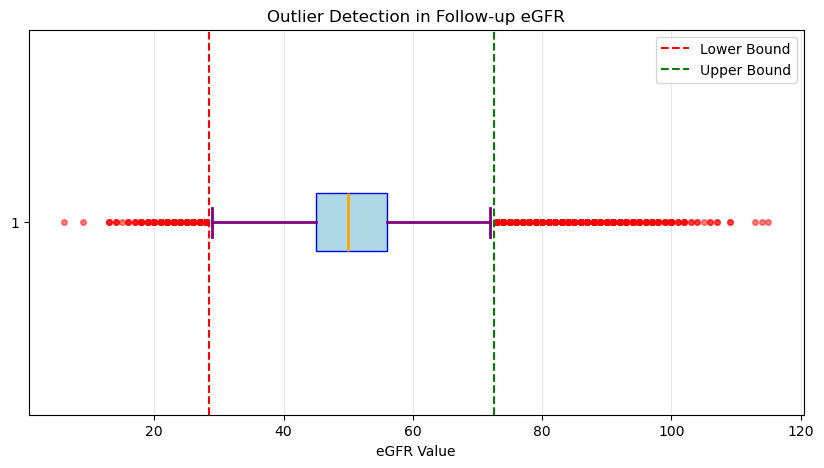

In [58]:

# Exercise 5: Outlier Detection Using IQR

import pandas as pd
import matplotlib.pyplot as plt

# Step 1: Select follow-up eGFR values
egfr = followup["egfr_value"]

# Step 2: Calculate Q1 and Q3
Q1 = egfr.quantile(0.25)
Q3 = egfr.quantile(0.75)

# Step 3: Calculate IQR
IQR = Q3 - Q1

# Step 4: Calculate outlier boundaries
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

# Step 5: Detect outliers
outliers = followup[
    (followup["egfr_value"] < lower_bound) |
    (followup["egfr_value"] > upper_bound)
]

print("\nTotal Outlier Records:", len(outliers))

# Step 6: Display detected outliers
display(outliers[
    ["patient_id", "study_day", "egfr_value"]
].head(10))

# Step 7: Visualize using box plot

plt.figure(figsize=(10, 5))

plt.boxplot(
    egfr.dropna(),
    vert=False,
    patch_artist=True,
    boxprops=dict(facecolor="lightblue", edgecolor="blue"),
    medianprops=dict(color="orange", linewidth=2),
    whiskerprops=dict(color="purple", linewidth=2),
    capprops=dict(color="purple", linewidth=2),
    flierprops=dict(
        marker="o",
        markerfacecolor="red",
        markeredgecolor="red",
        markersize=4,
        alpha=0.5
    )
)

plt.axvline(lower_bound, color="red",
            linestyle="--", label="Lower Bound")

plt.axvline(upper_bound, color="green",
            linestyle="--", label="Upper Bound")

plt.title("Outlier Detection in Follow-up eGFR")
plt.xlabel("eGFR Value")
plt.legend()
plt.grid(axis="x", alpha=0.3)
plt.show()



In [59]:

import pandas as pd

# Merge followup with baseline using patient_id
merged = pd.merge(
    followup,
    baseline,
    on="patient_id",
    how="left",
    validate="many_to_one",
    indicator=True,
    suffixes=("_followup", "_baseline")
)

# Display merged dataset
display(merged.head())

# Check dimensions
print("Merged Dataset Shape:", merged.shape)


,patient_id,randomized_flag_followup,itt_flag_followup,treatment_flag_followup,analysis_flag,egfr_value,baseline_egfr_followup,parameter_code,parameter_name,study_day,visit_number,visit_label,treatment_group,randomized_flag_baseline,itt_flag_baseline,treatment_flag_baseline,baseline_egfr_baseline,baseline_glp1,egfr_category,_merge
0,id0001,Y,Y,Y,Y,54,54,GFRBSCRT,GFR from Creatinine Adjusted for BSA (mL/min/1...,1,0,BASELINE,0,Y,Y,Y,54,N,Screening eGFR 45 to <60 mL/min/1.73m2,both
1,id0001,Y,Y,Y,Y,51,54,GFRBSCRT,GFR from Creatinine Adjusted for BSA (mL/min/1...,22,3,WEEK 3,0,Y,Y,Y,54,N,Screening eGFR 45 to <60 mL/min/1.73m2,both
2,id0001,Y,Y,Y,Y,61,54,GFRBSCRT,GFR from Creatinine Adjusted for BSA (mL/min/1...,91,13,WEEK 13,0,Y,Y,Y,54,N,Screening eGFR 45 to <60 mL/min/1.73m2,both
3,id0001,Y,Y,Y,Y,63,54,GFRBSCRT,GFR from Creatinine Adjusted for BSA (mL/min/1...,183,26,WEEK 26,0,Y,Y,Y,54,N,Screening eGFR 45 to <60 mL/min/1.73m2,both
4,id0001,Y,Y,Y,Y,53,54,GFRBSCRT,GFR from Creatinine Adjusted for BSA (mL/min/1...,362,52,WEEK 52,0,Y,Y,Y,54,N,Screening eGFR 45 to <60 mL/min/1.73m2,both


Merged Dataset Shape: (41800, 20)


In [60]:

# Check matching records
print(merged["_merge"].value_counts())

# Display unmatched records
unmatched = merged[merged["_merge"] == "left_only"]

print("Unmatched Records:", len(unmatched))
display(unmatched.head())


_merge
both          41800
left_only         0
right_only        0
Name: count, dtype: int64
Unmatched Records: 0


,patient_id,randomized_flag_followup,itt_flag_followup,treatment_flag_followup,analysis_flag,egfr_value,baseline_egfr_followup,parameter_code,parameter_name,study_day,visit_number,visit_label,treatment_group,randomized_flag_baseline,itt_flag_baseline,treatment_flag_baseline,baseline_egfr_baseline,baseline_glp1,egfr_category,_merge


In [61]:

# Display all merged column names
print(merged.columns.tolist())

# Compare baseline eGFR from both datasets
comparison = merged[
    ["baseline_egfr_followup", "baseline_egfr_baseline"]
]

print("eGFR values match:")
print(
    comparison["baseline_egfr_followup"].eq(
        comparison["baseline_egfr_baseline"]
    ).all()
)


['patient_id', 'randomized_flag_followup', 'itt_flag_followup', 'treatment_flag_followup', 'analysis_flag', 'egfr_value', 'baseline_egfr_followup', 'parameter_code', 'parameter_name', 'study_day', 'visit_number', 'visit_label', 'treatment_group', 'randomized_flag_baseline', 'itt_flag_baseline', 'treatment_flag_baseline', 'baseline_egfr_baseline', 'baseline_glp1', 'egfr_category', '_merge']
eGFR values match:
True


In [62]:

# Remove unnecessary duplicate attributes
if comparison["baseline_egfr_followup"].eq(
    comparison["baseline_egfr_baseline"]
).all():

    merged = merged.drop(columns=[
        "baseline_egfr_followup",
        "_merge"
    ])

    merged = merged.rename(columns={
        "baseline_egfr_baseline": "baseline_egfr"
    })

    print("Redundant eGFR column removed.")
else:
    print("eGFR mismatch detected. Investigate before cleaning.")

# Final dimensions and columns
print("Final Shape:", merged.shape)
print(merged.columns.tolist())

display(merged.head())


Redundant eGFR column removed.
Final Shape: (41800, 18)
['patient_id', 'randomized_flag_followup', 'itt_flag_followup', 'treatment_flag_followup', 'analysis_flag', 'egfr_value', 'parameter_code', 'parameter_name', 'study_day', 'visit_number', 'visit_label', 'treatment_group', 'randomized_flag_baseline', 'itt_flag_baseline', 'treatment_flag_baseline', 'baseline_egfr', 'baseline_glp1', 'egfr_category']


,patient_id,randomized_flag_followup,itt_flag_followup,treatment_flag_followup,analysis_flag,egfr_value,parameter_code,parameter_name,study_day,visit_number,visit_label,treatment_group,randomized_flag_baseline,itt_flag_baseline,treatment_flag_baseline,baseline_egfr,baseline_glp1,egfr_category
0,id0001,Y,Y,Y,Y,54,GFRBSCRT,GFR from Creatinine Adjusted for BSA (mL/min/1...,1,0,BASELINE,0,Y,Y,Y,54,N,Screening eGFR 45 to <60 mL/min/1.73m2
1,id0001,Y,Y,Y,Y,51,GFRBSCRT,GFR from Creatinine Adjusted for BSA (mL/min/1...,22,3,WEEK 3,0,Y,Y,Y,54,N,Screening eGFR 45 to <60 mL/min/1.73m2
2,id0001,Y,Y,Y,Y,61,GFRBSCRT,GFR from Creatinine Adjusted for BSA (mL/min/1...,91,13,WEEK 13,0,Y,Y,Y,54,N,Screening eGFR 45 to <60 mL/min/1.73m2
3,id0001,Y,Y,Y,Y,63,GFRBSCRT,GFR from Creatinine Adjusted for BSA (mL/min/1...,183,26,WEEK 26,0,Y,Y,Y,54,N,Screening eGFR 45 to <60 mL/min/1.73m2
4,id0001,Y,Y,Y,Y,53,GFRBSCRT,GFR from Creatinine Adjusted for BSA (mL/min/1...,362,52,WEEK 52,0,Y,Y,Y,54,N,Screening eGFR 45 to <60 mL/min/1.73m2


In [63]:

merged.to_csv(
    "smart_c_merged.csv",
    index=False
)

print("Merged dataset saved successfully!")


Merged dataset saved successfully!


In [64]:

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler, StandardScaler


# Select columns for scaling
numeric_columns = ["baseline_egfr", "egfr_value"]

# Check original statistics
print("Original Data Statistics:")
display(merged[numeric_columns].describe())


# Create a separate DataFrame
normalized_data = merged.copy()

# Initialize MinMaxScaler
minmax_scaler = MinMaxScaler()

# Apply Min-Max normalization
normalized_data[numeric_columns] = minmax_scaler.fit_transform(
    merged[numeric_columns]
)

print("Min-Max Normalized Data:")
display(normalized_data[numeric_columns].head(10))

# Check minimum and maximum
print("\nMinimum values:")
print(normalized_data[numeric_columns].min())

print("\nMaximum values:")
print(normalized_data[numeric_columns].max())


Original Data Statistics:


,baseline_egfr,egfr_value
count,41800.000000,41800.000000
mean,55.716986,50.846220
std,17.967595,9.479448
min,6.000000,6.000000
25%,42.000000,45.000000
50%,54.000000,50.000000
75%,69.000000,56.000000
max,115.000000,115.000000


Min-Max Normalized Data:


,baseline_egfr,egfr_value
0,0.440367,0.440367
1,0.440367,0.412844
2,0.440367,0.504587
3,0.440367,0.522936
4,0.440367,0.431193
5,0.440367,0.376147
6,0.440367,0.284404
7,0.440367,0.477064
8,0.440367,0.486239
9,0.192661,0.192661



Minimum values:
baseline_egfr    0.0
egfr_value       0.0
dtype: float64

Maximum values:
baseline_egfr    1.0
egfr_value       1.0
dtype: float64


In [65]:

# Create another DataFrame
standardized_data = merged.copy()

# Initialize StandardScaler
standard_scaler = StandardScaler()

# Apply Z-score standardization
standardized_data[numeric_columns] = standard_scaler.fit_transform(
    merged[numeric_columns]
)

print("Z-Score Standardized Data:")
display(standardized_data[numeric_columns].head(10))

# Check mean and standard deviation
print("\nMean:")
print(standardized_data[numeric_columns].mean())

print("\nStandard Deviation:")
print(standardized_data[numeric_columns].std(ddof=0))


Z-Score Standardized Data:


,baseline_egfr,egfr_value
0,-0.095561,0.332701
1,-0.095561,0.016223
2,-0.095561,1.071149
3,-0.095561,1.282134
4,-0.095561,0.227208
5,-0.095561,-0.405748
6,-0.095561,-1.460674
7,-0.095561,0.754671
8,-0.095561,0.860164
9,-1.598285,-2.515601



Mean:
baseline_egfr   -2.617789e-17
egfr_value      -7.326410e-17
dtype: float64

Standard Deviation:
baseline_egfr    1.0
egfr_value       1.0
dtype: float64


In [66]:

# Compare original, normalized and standardized eGFR

comparison = pd.DataFrame({
    "Original eGFR": merged["egfr_value"],
    "Min-Max eGFR": normalized_data["egfr_value"],
    "Z-Score eGFR": standardized_data["egfr_value"]
})

display(comparison.head(10))


,Original eGFR,Min-Max eGFR,Z-Score eGFR
0,54,0.440367,0.332701
1,51,0.412844,0.016223
2,61,0.504587,1.071149
3,63,0.522936,1.282134
4,53,0.431193,0.227208
5,47,0.376147,-0.405748
6,37,0.284404,-1.460674
7,58,0.477064,0.754671
8,59,0.486239,0.860164
9,27,0.192661,-2.515601


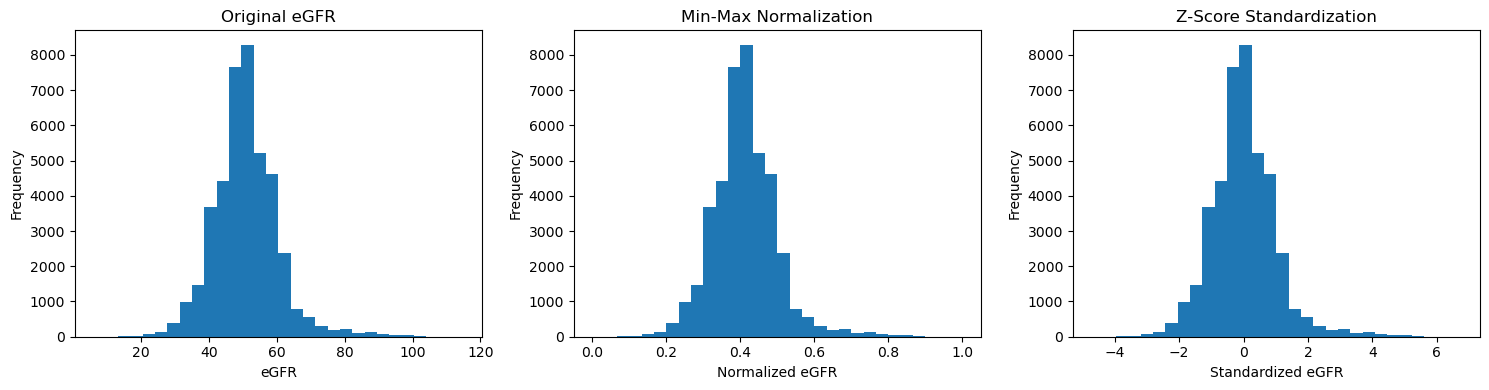

In [67]:

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Original
axes[0].hist(merged["egfr_value"], bins=30)
axes[0].set_title("Original eGFR")
axes[0].set_xlabel("eGFR")

# Min-Max
axes[1].hist(normalized_data["egfr_value"], bins=30)
axes[1].set_title("Min-Max Normalization")
axes[1].set_xlabel("Normalized eGFR")

# Z-Score
axes[2].hist(standardized_data["egfr_value"], bins=30)
axes[2].set_title("Z-Score Standardization")
axes[2].set_xlabel("Standardized eGFR")

for ax in axes:
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()
